# IR 01b — convert + label check

This worked example starts from the **native acquisition checkpoint**, not the prefiltered baseline. Inspect, hypothesize, implement, and verify before fitting the unchanged classifier. No synthetic corruptions are added to make a strategy appear successful.

All options exclude every observation of held-out molecules and copy validation/test byte-for-byte. Only training is changed. Model features always end as the same finite **500-point grid with 12 binary targets**. Audit columns never become features. This strategy combines several changes; a performance difference cannot be attributed to just one of them.

### Reading and presenting this notebook

The bullet points above each code cell explain what to notice; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


**What to notice**

- Select this example's signal, bounds, resampling, and cleansing policies and its own output folder.
- Exclude frozen validation/test molecular observations before any training-data changes.


In [1]:
from pathlib import Path
import sys
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates = [parent, parent / '02_ir_functional_groups']
    module = next((p for p in candidates if (p / 'ir_carpentry.py').is_file()), None)
    if module is not None:
        sys.path.insert(0, str(module)); sys.path.insert(0, str(module / 'examples')); break
else:
    raise FileNotFoundError('Keep the examples folder inside the IR module.')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ir_carpentry import (LABELS, load_native, ensure_frozen_evaluation, training_pool,
                         prepare_training, save_carpentry, validate_frozen_evaluation)
from ir_example_support import examine_native, cleanse_training, validate_tables

MODULE = module.resolve()
OUTPUT_DIR = MODULE / 'examples/outputs/01b_convert_transmittance'
SIGNAL_POLICY = 'convert_transmittance'
BOUNDS_POLICY = 'require_full_coverage'
RESAMPLING = 'linear'
CLEANSING = 'smarts_label_check'
source, source_file = load_native(MODULE)
holdouts, grid, contract = ensure_frozen_evaluation(MODULE, source)
pool, excluded = training_pool(source, holdouts)
print(f'Native candidates: {len(pool):,}; held-out observations excluded: {excluded:,}')
print('Frozen grid/labels:', len(grid), len(LABELS), 'Frozen test hash:', contract['sha256']['test'])

[18:11:58] WARNING: not removing hydrogen atom without neighbors
[18:11:58] WARNING: not removing hydrogen atom without neighbors
[18:11:58] WARNING: not removing hydrogen atom without neighbors
[18:11:58] WARNING: not removing hydrogen atom without neighbors


Native candidates: 9,027; held-out observations excluded: 1,974
Frozen grid/labels: 500 12 Frozen test hash: fde8bb1a7d770dc498299a09141b0ba9108b3366b06e4c34697506f9af4cc2a1


## Examine — prompt to your coding assistant

> Inspect native TRAINING candidates for categorical outliers, missing/nonbinary labels, invalid/duplicate molecular identities, NaN/Inf inside arrays, unequal lengths, reversed/repeated coordinates, coverage and signal-unit differences. Count absorbance, transmittance and unsupported signals. Inspect valid ranges without guessing percent from amplitude. Show descriptive quantiles, coverage and category frequencies. Distinguish statistical anomalies from legitimate rare chemistry. Do not tune any rule on held-out spectra or test scores.

**What to notice**

- Examine native signal/coordinate units, NaNs, array lengths, coverage, label categories, duplicates, and statistical anomalies.
- Use the preceding hypothesis/prompt to explain what to fix; inspect flagged observations rather than assuming they are wrong.


Native training-candidate units (not the held-out reference):


rows
xunits      yunits             
1/CM        ABSORBANCE     4533
            REFLECTANCE       1
            TRANSMITTANCE  2607
MICROMETERS TRANSMITTANCE  1886

,SMILES,CAS_NO,Vinylic,Arene,Alcohol,Ether,Amine,Nitrile,Aldehyde,Ketone,CarboxylAcid,Ester,Amide,AcidChloride
missing_cells,0,564,0,0,0,0,0,0,0,0,0,0,0,0


,positive,invalid_or_missing
Vinylic,1226,0
Arene,5404,0
Alcohol,2169,0
Ether,2483,0
Amine,1665,0
Nitrile,358,0
Aldehyde,172,0
Ketone,771,0
CarboxylAcid,621,0
Ester,1124,0


[18:11:59] WARNING: not removing hydrogen atom without neighbors
[18:11:59] WARNING: not removing hydrogen atom without neighbors
[18:11:59] WARNING: not removing hydrogen atom without neighbors
[18:11:59] WARNING: not removing hydrogen atom without neighbors


Invalid SMILES / duplicate canonical molecules: 0 50


,rows
status,
valid_explicit_units,8457
transmittance_outside_explicit_unit_range,569
unsupported_signal_units,1


,native_points,low,high,signal_min,signal_max,coverage
0.00,825.00,92.08800,626.291727,0.000000,0.00300,0.00800
0.01,825.00,246.50372,3780.000000,0.000000,0.00900,0.94112
0.50,1790.00,550.00000,3999.500000,0.000000,0.88867,1.00000
0.99,3915.74,677.69760,5017.561465,0.122679,3.00000,1.00000
1.00,7152.00,1005.74200,10438.413361,0.312025,4.00000,1.00000


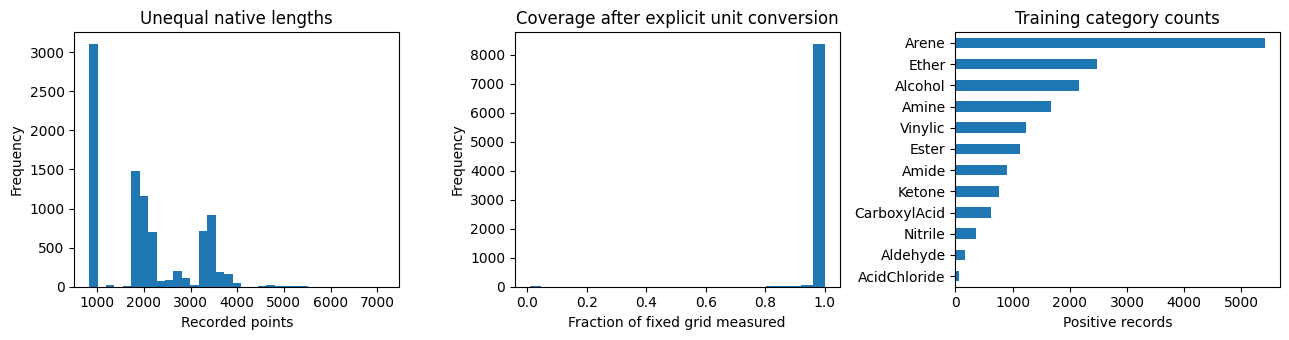

In [2]:
native_statistics = examine_native(pool, grid, OUTPUT_DIR)

## Carpentry — prompted hypothesis

> Hypothesis: some excluded transmittance spectra can be useful after correct conversion. Convert explicit fraction/percent transmittance to absorbance using A = -log10(T), and micrometres to cm^-1. Reject nonphysical transmittance without clipping or guessing units. Trim measured excess, require full coverage, and linearly downsample/upsample to 500 points. Check labels against the documented SMARTS and correct only mismatches, reporting zero changes honestly if already consistent. These definitions are operational, not independent chemical ground truth.

**What to notice**

- Convert supported transmittance to absorbance, require full coverage, and linearly resample.
- Check categorical labels against SMILES/SMARTS and audit inconsistent training records.
- Review the action audit, label counts, padded/resampled records, and uniform example spectra.


Stored labels corrected to the documented operational SMARTS: 0
This is internal consistency, not independent experimental ground-truth validation.


events
action   reason                                                    
kept     cropped_and_interpolated                              4533
         transmittance_to_absorbance;cropped_and_interpo...     287
rejected incomplete_measured_coverage                          3155
         invalid_identity                                       564
         transmittance_outside_explicit_unit_range              487
         unsupported_signal_units                                 1

After spectral preparation: 4,820; after additional cleansing: 4,820
Final resampling actions: {'downsampled_linear': 4820}
Padded training presentations: 0


,before additional cleansing,after
Vinylic,730,730
Arene,2630,2630
Alcohol,1203,1203
Ether,1288,1288
Amine,567,567
Nitrile,221,221
Aldehyde,125,125
Ketone,458,458
CarboxylAcid,342,342
Ester,579,579


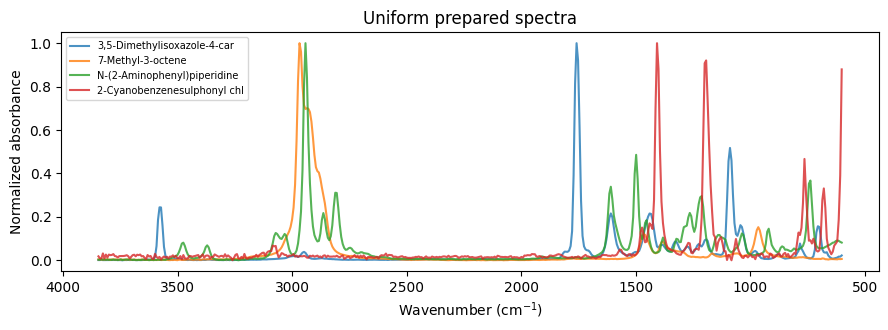

In [3]:
prepared, audit = prepare_training(pool, grid, SIGNAL_POLICY, BOUNDS_POLICY,
    minimum_coverage=.8, resampling=RESAMPLING)
before_rows = len(prepared)
before_counts = prepared[LABELS].sum()
train, additional_audit = cleanse_training(prepared, CLEANSING)
audit = pd.concat([audit, additional_audit], ignore_index=True)
display(audit.groupby(['action', 'reason']).size().rename('events').to_frame())
print(f'After spectral preparation: {before_rows:,}; after additional cleansing: {len(train):,}')
print('Final resampling actions:', train.resampling_action.value_counts().to_dict())
print('Padded training presentations:', int(train.padded_points.gt(0).sum()))
display(pd.DataFrame({'before additional cleansing': before_counts, 'after': train[LABELS].sum()}))
fig, ax = plt.subplots(figsize=(9, 3.4))
for _, row in train.head(4).iterrows():
    ax.plot(grid, row.IR, label=str(row.Name)[:27], alpha=.8)
ax.invert_xaxis(); ax.set(xlabel='Wavenumber (cm$^{-1}$)', ylabel='Normalized absorbance', title='Uniform prepared spectra')
ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'prepared_spectra.png', dpi=140); plt.show()

## Verify the uniform handoff — final prompted action

> Save and reload the prepared training file, labels, manifest and audit. Assert that every saved feature row has exactly the same 500 finite values on the frozen grid; targets are 12 binary columns in the fixed order. Report the model matrix shape, normalization range, positive category counts and duplicate presentations. Assert no held-out molecule is present in training and check exact validation/test file hashes. Do not start training until all checks pass.

**What to notice**

- Save this strategy's training output alongside the byte-identical frozen evaluation tables and manifest.
- Reload and check finite normalized 500-point arrays, 12 binary labels, and disjoint identities; point static IR 02 at the printed directory.


In [4]:
choices = dict(example='01b', signal_policy=SIGNAL_POLICY, bounds_policy=BOUNDS_POLICY,
    resampling=RESAMPLING, minimum_coverage=.8, normalization='per_spectrum_minmax_absorbance',
    cleansing=CLEANSING, training_identity_guard=True)
manifest = save_carpentry(MODULE, OUTPUT_DIR, train, source_file, choices, audit, len(source))
tables = {name: pd.read_parquet(OUTPUT_DIR / f'IR_{name}.parquet') for name in ('train', 'validation', 'test')}
validate_tables(tables, grid)
validate_frozen_evaluation(MODULE, OUTPUT_DIR, grid)
features = np.vstack(tables['train'].IR).astype(np.float32)
assert features.shape == (len(tables['train']), 500)
assert features.min() >= -1e-6 and features.max() <= 1 + 1e-6
assert len(LABELS) == 12
print('PASS: saved/reloaded uniform matrix', features.shape, '; dtype', features.dtype)
print('PASS: 12 binary labels, fixed coordinate grid, no training/held-out overlap, unchanged evaluation hashes.')
print('Rows:', manifest['rows'])
print("Ready for static IR 02: CARPENTRY_DIR = Path('examples/outputs/01b_convert_transmittance')")

PASS: saved/reloaded uniform matrix (4820, 500) ; dtype float32
PASS: 12 binary labels, fixed coordinate grid, no training/held-out overlap, unchanged evaluation hashes.
Rows: {'input': 11001, 'train': 4820, 'validation': 975, 'test': 975}
Ready for static IR 02: CARPENTRY_DIR = Path('examples/outputs/01b_convert_transmittance')


## Evaluate honestly

The next step is the same IR 02 classifier, not a specially tuned model for this example. IR 03 assembles observed validation/test results, epoch counts and stopping reasons. These single-seed fits and bundled interventions do not establish a causal benefit for any individual step. The baseline may outperform a more elaborate strategy. Keep test scores for final reporting rather than choosing policies by them.